# 02 · Exploratory data analysis

Questions 19–36 from `analysis_questions.md`. Loads the cleaned parquet files from `00_load_clean`.

**Audit rules applied:**
- Acquisition and cohorts use the **first order date**, not `join_date` (18% of first orders precede it).
- Money is **net sales excluding tax**, and profit is **gross profit**.
- Revenue metrics exclude cancelled and returned orders.
- Customer type (one-time or recurring) counts all placed orders, the same as Power BI.

Every key result is logged with `note()` and saved to `output/eda_findings.csv`. Charts go to `output/figures/`.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.tsa.seasonal import STL
from src.metrics import DATA_DIR, OUTPUT_DIR, DATA_END
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
TEAL, AMBER, NAVY, CORAL, SLATE = "#0E7C86", "#F2A541", "#14213D", "#E4572E", "#5B6C8F"
sns.set_theme(style="whitegrid", palette=[TEAL, AMBER, NAVY, CORAL, SLATE])
FIG = OUTPUT_DIR / "figures"; FIG.mkdir(parents=True, exist_ok=True)
L = lambda v: f"₹{v/1e5:,.1f} L"   # lakh formatting

cust = pd.read_parquet(DATA_DIR / "customers.parquet")
lines = pd.read_parquet(DATA_DIR / "lines.parquet")
orders = pd.read_parquet(DATA_DIR / "orders.parquet")
prod = pd.read_parquet(DATA_DIR / "products.parquet")
rl = lines[lines["is_revenue"]].copy()          # revenue lines
ro = orders[orders["is_revenue"]].copy()        # revenue orders
ro["month"] = ro["order_date"].dt.to_period("M").dt.to_timestamp()

findings = []
def note(q, topic, text):
    findings.append(dict(q=q, topic=topic, finding=text)); print(f"Q{q} · {topic}: {text}")
def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight"); plt.show()
print(len(cust), "customers |", len(orders), "orders |", len(ro), "revenue orders |", len(rl), "revenue lines")

300 customers | 405 orders | 386 revenue orders | 1431 revenue lines


## A. Sales and profit over time

### Q19 · Monthly trend and seasonality

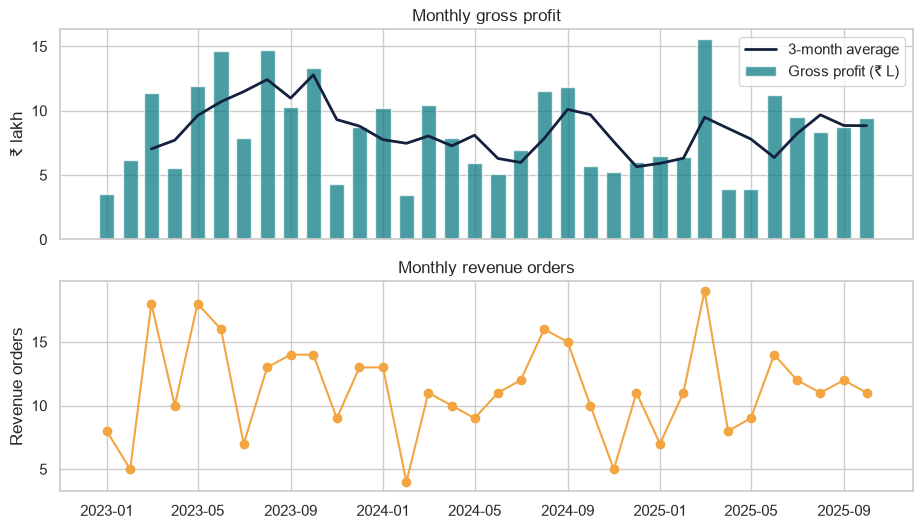

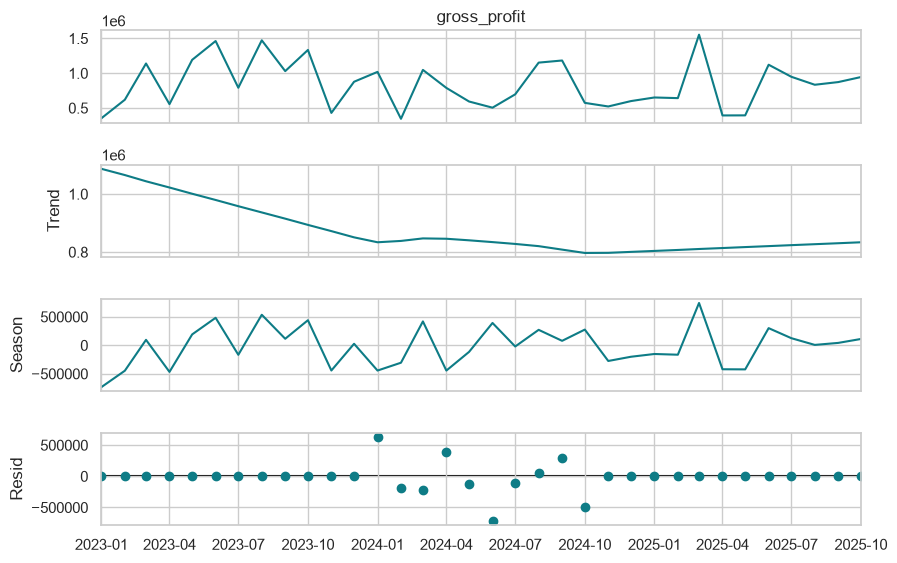

,count,mean,std,min,25%,50%,75%,max
orders,34.00,11.35,3.70,4.00,9.00,11.00,13.75,19.00
net_sales,34.00,"3,183,020.10","1,169,315.31","1,324,570.94","2,270,079.10","3,064,703.99","4,050,989.03","5,877,647.94"
gross_profit,34.00,"842,452.76","342,333.48","345,126.93","578,917.53","812,762.32","1,103,409.60","1,553,775.91"
margin,34.00,0.26,0.03,0.17,0.24,0.26,0.28,0.32
customers,34.00,10.91,3.50,4.00,9.00,11.00,13.00,18.00


Q19 · Trend & seasonality: Avg 11.4 revenue orders and ₹8.4 L gross profit per month (CV 41%). STL seasonal strength 0.62, trend strength 0.17, but estimated from fewer than 3 yearly cycles, so any seasonality is unconfirmed. Best month on average: Mar, weakest: Nov. Weekday mix chi-square p=0.51 (no weekday effect).


In [2]:
m = ro.groupby("month").agg(orders=("order_id", "count"), net_sales=("net_sales", "sum"),
                            gross_profit=("gross_profit", "sum"), customers=("customer_id", "nunique"))
m = m.reindex(pd.date_range("2023-01-01", "2025-10-01", freq="MS"), fill_value=0)
m["margin"] = m["gross_profit"] / m["net_sales"]
m["gp_3m"] = m["gross_profit"].rolling(3).mean()

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].bar(m.index, m["gross_profit"] / 1e5, width=20, color=TEAL, alpha=.75, label="Gross profit (₹ L)")
axes[0].plot(m.index, m["gp_3m"] / 1e5, color=NAVY, lw=2, label="3-month average")
axes[0].set_ylabel("₹ lakh"); axes[0].legend(loc="upper right"); axes[0].set_title("Monthly gross profit")
axes[1].plot(m.index, m["orders"], marker="o", color=AMBER); axes[1].set_ylabel("Revenue orders")
axes[1].set_title("Monthly revenue orders")
save(fig, "q19_monthly_trend")

stl = STL(m["gross_profit"], period=12, robust=True).fit()
season_strength = max(0, 1 - stl.resid.var() / (stl.resid + stl.seasonal).var())
trend_strength = max(0, 1 - stl.resid.var() / (stl.resid + stl.trend).var())
fig = stl.plot(); fig.set_size_inches(10, 6); save(fig, "q19_stl")

moy = ro.assign(mo=ro.order_date.dt.month).groupby("mo")["gross_profit"].sum() / ro.order_date.dt.year.nunique()
dow = ro.assign(d=ro.order_date.dt.day_name()).groupby("d")["order_id"].count()
chi = stats.chisquare(dow.values)
display(m[["orders", "net_sales", "gross_profit", "margin", "customers"]].describe().T)
note(19, "Trend & seasonality",
     f"Avg {m.orders.mean():.1f} revenue orders and {L(m.gross_profit.mean())} gross profit per month "
     f"(CV {m.gross_profit.std()/m.gross_profit.mean():.0%}). STL seasonal strength {season_strength:.2f}, "
     f"trend strength {trend_strength:.2f}, but estimated from fewer than 3 yearly cycles, so any seasonality is unconfirmed. "
     f"Best month on average: {pd.Timestamp(2000, moy.idxmax(), 1):%b}, weakest: {pd.Timestamp(2000, moy.idxmin(), 1):%b}. "
     f"Weekday mix chi-square p={chi.pvalue:.2f} ({'no' if chi.pvalue > .05 else 'a'} weekday effect).")

### Q20 · Like-for-like growth (Jan–Oct each year)

In [3]:
ytd = ro[ro.order_date.dt.month <= 10].assign(year=lambda d: d.order_date.dt.year)
y = ytd.groupby("year").agg(orders=("order_id", "count"), customers=("customer_id", "nunique"),
                            net_sales=("net_sales", "sum"), gross_profit=("gross_profit", "sum"))
y["margin"] = y.gross_profit / y.net_sales
y["gp_yoy"] = y.gross_profit.pct_change()
y["orders_yoy"] = y.orders.pct_change()
display(y)
note(20, "Like-for-like growth",
     f"Jan-Oct gross profit: 2023 {L(y.gross_profit[2023])}, 2024 {L(y.gross_profit[2024])} ({y.gp_yoy[2024]:+.0%}), "
     f"2025 {L(y.gross_profit[2025])} ({y.gp_yoy[2025]:+.0%}). Orders {y.orders[2023]} → {y.orders[2024]} → {y.orders[2025]}; "
     f"active customers {y.customers[2023]} → {y.customers[2024]} → {y.customers[2025]}.")

,orders,customers,net_sales,gross_profit,margin,gp_yoy,orders_yoy
year,,,,,,,
2023,123,108,"35,843,511.86","9,950,736.76",0.28,NaN,NaN
2024,111,84,"31,693,210.62","7,905,253.39",0.25,-0.21,-0.10
2025,114,90,"31,169,074.32","8,358,113.86",0.27,0.06,0.03


Q20 · Like-for-like growth: Jan-Oct gross profit: 2023 ₹99.5 L, 2024 ₹79.1 L (-21%), 2025 ₹83.6 L (+6%). Orders 123 → 111 → 114; active customers 108 → 84 → 90.


### Q21 · What drives average order value?

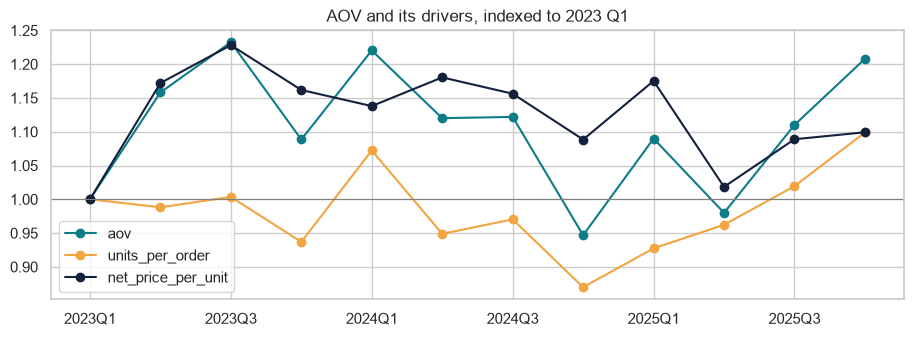

,orders,aov,units_per_order,net_price_per_unit,discount_rate
qtr,,,,,
2023Q1,31,"253,735.54",5.13,"49,470.45",0.12
2023Q2,44,"293,863.14",5.07,"57,981.96",0.11
2023Q3,34,"312,723.57",5.15,"60,757.72",0.07
2023Q4,36,"276,192.02",4.81,"57,473.48",0.08
2024Q1,28,"309,622.57",5.50,"56,295.01",0.09
2024Q2,30,"284,190.67",4.87,"58,395.34",0.10
2024Q3,43,"284,678.16",4.98,"57,201.69",0.09
2024Q4,26,"240,230.86",4.46,"53,844.85",0.11
2025Q1,37,"276,541.66",4.76,"58,136.60",0.08


Q21 · AOV drivers: AOV ranges ₹2.4 L-₹3.1 L by quarter. Correlation of log AOV with units/order 0.70 vs with net price/unit 0.67: AOV moves mainly with basket size (units). Discount rate range 7.4%-12.2%.


In [4]:
q = ro.assign(qtr=ro.order_date.dt.to_period("Q").astype(str)).groupby("qtr").agg(
    orders=("order_id", "count"), net_sales=("net_sales", "sum"), units=("units", "sum"),
    lines=("lines", "sum"), gross=("gross_amount", "sum"))
q["aov"] = q.net_sales / q.orders
q["units_per_order"] = q.units / q.orders
q["net_price_per_unit"] = q.net_sales / q.units
q["discount_rate"] = 1 - q.net_sales / q.gross
# log decomposition: ln(AOV) = ln(units/order) + ln(price/unit)
r1 = np.corrcoef(np.log(q.aov), np.log(q.units_per_order))[0, 1]
r2 = np.corrcoef(np.log(q.aov), np.log(q.net_price_per_unit))[0, 1]
fig, ax = plt.subplots(figsize=(11, 3.5))
(q[["aov", "units_per_order", "net_price_per_unit"]] / q[["aov", "units_per_order", "net_price_per_unit"]].iloc[0]).plot(ax=ax, marker="o")
ax.axhline(1, color="grey", lw=.8); ax.set_title("AOV and its drivers, indexed to 2023 Q1"); ax.set_xlabel("")
save(fig, "q21_aov_drivers")
display(q[["orders", "aov", "units_per_order", "net_price_per_unit", "discount_rate"]])
note(21, "AOV drivers",
     f"AOV ranges {L(q.aov.min())}-{L(q.aov.max())} by quarter. Correlation of log AOV with units/order {r1:.2f} "
     f"vs with net price/unit {r2:.2f}: AOV moves mainly with {'basket size (units)' if abs(r1) > abs(r2) else 'price mix'}. "
     f"Discount rate range {q.discount_rate.min():.1%}-{q.discount_rate.max():.1%}.")

## B. Customers and retention

In [5]:
# Customer timeline built from ALL placed orders (behaviour), money from revenue orders
po = orders.sort_values(["customer_id", "order_date"]).copy()
po["n"] = po.groupby("customer_id").cumcount() + 1
first = po[po.n == 1].set_index("customer_id")
second = po[po.n == 2].set_index("customer_id")
buyers = cust[cust.lifetime_orders > 0].set_index("customer_id").copy()
buyers["first_date"] = first.order_date
buyers["second_date"] = second.order_date
buyers["first_q"] = buyers.first_date.dt.to_period("Q")
buyers["days_observed"] = (DATA_END - buyers.first_date).dt.days
buyers["gap_1_2"] = (buyers.second_date - buyers.first_date).dt.days
buyers["recurring"] = buyers.lifetime_orders >= 2
print(len(buyers), "buyers")

220 buyers


### Q22 · Cohort retention (by first-order quarter)

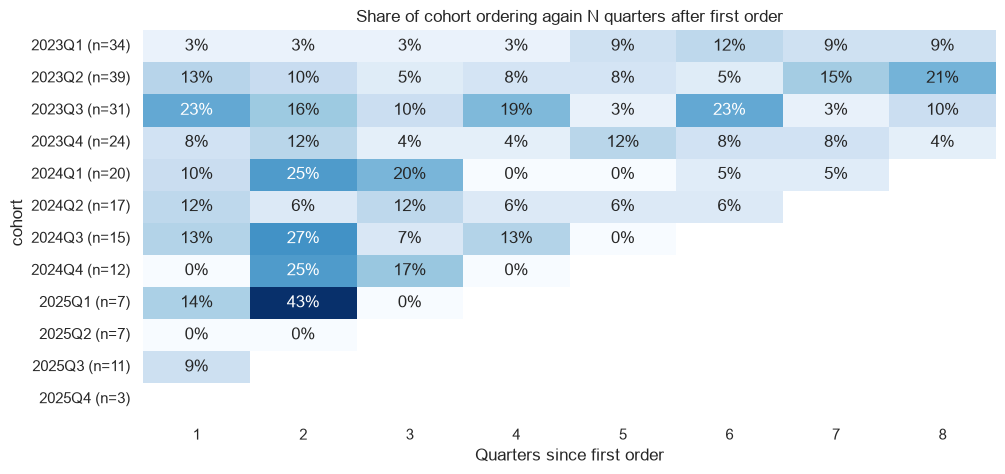

,repeat share,eligible buyers
90,0.10,212.00
180,0.20,202.00
365,0.34,186.00


Q22 · Cohort retention: Of buyers observed long enough, 10% order again within 90 days, 20% within 180 days, 34% within 365 days. Cohort sizes shrink from 32 buyers/quarter in 2023 to 7 in the last 4 quarters.


In [6]:
po["cohort"] = po.customer_id.map(buyers.first_q)
po["q_idx"] = (po.order_date.dt.to_period("Q") - po.cohort).apply(lambda x: x.n)
size = buyers.groupby("first_q").size()
active = po.groupby(["cohort", "q_idx"]).customer_id.nunique().unstack(fill_value=0)
ret = active.div(size, axis=0)
last_q = DATA_END.to_period("Q")
for c in ret.index:                      # blank out quarters that have not happened yet for this cohort
    ret.loc[c, [k for k in ret.columns if (c + k) > last_q]] = np.nan
fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(ret.iloc[:, 1:9], annot=True, fmt=".0%", cmap="Blues", cbar=False, ax=ax, mask=ret.iloc[:, 1:9].isna(),
            yticklabels=[f"{c} (n={size[c]})" for c in ret.index])
ax.grid(False); ax.set_title("Share of cohort ordering again N quarters after first order"); ax.set_xlabel("Quarters since first order")
save(fig, "q22_cohort_heatmap")
def within(days):
    elig = buyers[buyers.days_observed >= days]
    return (elig.gap_1_2 <= days).mean(), len(elig)
w = {d: within(d) for d in (90, 180, 365)}
display(pd.DataFrame(w, index=["repeat share", "eligible buyers"]).T)
note(22, "Cohort retention",
     f"Of buyers observed long enough, {w[90][0]:.0%} order again within 90 days, {w[180][0]:.0%} within 180 days, "
     f"{w[365][0]:.0%} within 365 days. Cohort sizes shrink from {size.iloc[:4].mean():.0f} buyers/quarter in 2023 "
     f"to {size.iloc[-4:].mean():.0f} in the last 4 quarters.")

### Q23 · Time between first and second order (Kaplan–Meier, censored)

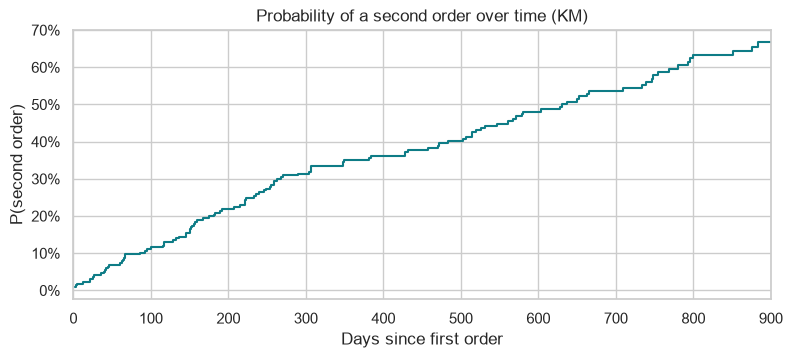

Q23 · Time to 2nd order: Median gap 1st→2nd order 254 days (IQR 131-527). KM probability of a 2nd order: 10% by 90 d, 20% by 180 d, 35% by 1 yr, 54% by 2 yrs. 38% of second orders come after a year, so 'lost' should not be declared before ~12 months of silence.


In [7]:
# event = second order; censored at DATA_END for one-time buyers
dur = buyers.gap_1_2.fillna(buyers.days_observed).clip(lower=0)
event = buyers.gap_1_2.notna()
def kaplan_meier(t, e):
    df = pd.DataFrame({"t": t, "e": e}).sort_values("t")
    out, s, n = [], 1.0, len(df)
    for time, g in df.groupby("t"):
        d = g.e.sum()
        if d: s *= 1 - d / n
        out.append((time, s)); n -= len(g)
    return pd.DataFrame(out, columns=["t", "S"]).set_index("t").S
S = kaplan_meier(dur, event)
P = 1 - S
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.step(P.index, P.values, where="post", color=TEAL); ax.set_xlim(0, 900)
ax.set_xlabel("Days since first order"); ax.set_ylabel("P(second order)")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.set_title("Probability of a second order over time (KM)")
save(fig, "q23_km_second_order")
at = lambda d: P[P.index <= d].iloc[-1] if (P.index <= d).any() else 0
gaps = buyers.gap_1_2.dropna()
# after how long does the hazard flatten? share of eventual repeats happening within N days
late = (gaps > 365).mean()
note(23, "Time to 2nd order",
     f"Median gap 1st→2nd order {gaps.median():.0f} days (IQR {gaps.quantile(.25):.0f}-{gaps.quantile(.75):.0f}). "
     f"KM probability of a 2nd order: {at(90):.0%} by 90 d, {at(180):.0%} by 180 d, {at(365):.0%} by 1 yr, {at(730):.0%} by 2 yrs. "
     f"{late:.0%} of second orders come after a year, so 'lost' should not be declared before ~12 months of silence.")

### Q24 · Why did acquisition fall?

C:\Users\hp\anaconda3\Lib\site-packages\pandas\plotting\_matplotlib\core.py:2062: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim((start_edge, end_edge))


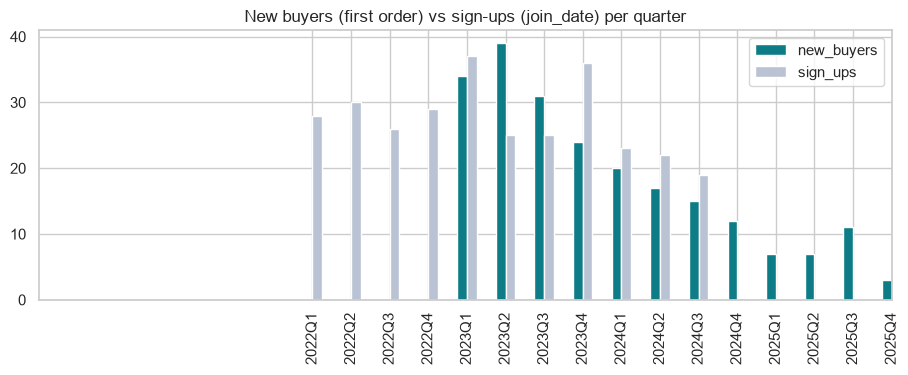

buyer_status,first order,repeat order,repeat_share
order_date,,,
2023,121,24,0.17
2024,59,68,0.54
2025,28,86,0.75


Q24 · Acquisition decline: New buyers by year: {2023: 128, 2024: 64, 2025: 28}. Sign-ups (join_date) by year: {2022: 113, 2023: 123, 2024: 64}; the last sign-up is 25 Sep 2024, with none in the following 13 months. New buyers track sign-ups, so the drop is a top-of-funnel problem (or an extract cut-off), not a conversion problem. 80 registered customers are still unconverted. Repeat orders rose from 17% to 75% of orders.


In [8]:
newq = buyers.groupby("first_q").size().rename("new_buyers")
joins = cust.dropna(subset=["join_date"]).assign(q=lambda d: d.join_date.dt.to_period("Q")).groupby("q").size().rename("sign_ups")
acq = pd.concat([newq, joins], axis=1).fillna(0).astype(int)
acq = acq[(acq.index >= pd.Period("2022Q1")) & (acq.index <= pd.Period("2025Q4"))]
fig, ax = plt.subplots(figsize=(11, 3.5))
acq.plot(kind="bar", ax=ax, color=[TEAL, "#B9C3D3"]); ax.set_title("New buyers (first order) vs sign-ups (join_date) per quarter")
ax.set_xlabel(""); save(fig, "q24_acquisition")
# share of orders by customer tenure: are we just running out of new people?
po["buyer_status"] = np.where(po.n == 1, "first order", "repeat order")
mix = po[po.is_revenue].groupby([po.order_date.dt.year, "buyer_status"]).order_id.count().unstack()
mix["repeat_share"] = mix["repeat order"] / mix.sum(axis=1)
display(mix)
pool_left = cust[(cust.lifetime_orders == 0)].shape[0]
signup_last = joins[joins.index >= pd.Period("2025Q1")].sum()
note(24, "Acquisition decline",
     f"New buyers by year: {buyers.first_date.dt.year.value_counts().sort_index().to_dict()}. "
     f"Sign-ups (join_date) by year: {cust.join_date.dt.year.value_counts().sort_index().to_dict()}; the last sign-up is "
     f"{cust.join_date.max():%d %b %Y}, with none in the following {(DATA_END - cust.join_date.max()).days // 30} months. New buyers track "
     f"sign-ups, so the drop is a top-of-funnel problem (or an extract cut-off), not a conversion problem. "
     f"{pool_left} registered customers are still unconverted. Repeat orders rose from {mix.repeat_share.iloc[0]:.0%} to "
     f"{mix.repeat_share.iloc[-1]:.0%} of orders.")

### Q25 · Who are the never-ordered customers?

In [9]:
c2 = cust.copy()
c2["age"] = ((DATA_END - c2.birth_date).dt.days / 365.25)
c2["status"] = np.where(c2.lifetime_orders > 0, "Buyer", "Never ordered")
prof = pd.concat({
    "segment": pd.crosstab(c2.segment, c2.status, normalize="columns"),
    "gender": pd.crosstab(c2.gender, c2.status, normalize="columns"),
    "join year": pd.crosstab(c2.join_date.dt.year, c2.status, normalize="columns"),
})
display(prof.style.format("{:.0%}"))
age_t = stats.mannwhitneyu(c2[c2.status == "Buyer"].age.dropna(), c2[c2.status != "Buyer"].age.dropna())
seg_chi = stats.chi2_contingency(pd.crosstab(c2.segment, c2.status))
top_states = c2[c2.status != "Buyer"].state.value_counts().head(3).to_dict()
note(25, "Never-ordered profile",
     f"{(c2.status != 'Buyer').sum()} never-ordered customers. Median age {c2[c2.status != 'Buyer'].age.median():.0f} vs "
     f"{c2[c2.status == 'Buyer'].age.median():.0f} for buyers (p={age_t.pvalue:.2f}); segment difference p={seg_chi.pvalue:.2f}. "
     f"Top states: {top_states}. They look like buyers demographically: non-conversion is not explained by profile.")

Q25 · Never-ordered profile: 80 never-ordered customers. Median age 44 vs 43 for buyers (p=0.57); segment difference p=0.56. Top states: {'Maharashtra': 18, 'Gujarat': 11, 'Karnataka': 8}. They look like buyers demographically: non-conversion is not explained by profile.


### Q26 · RFM segmentation

,customers,avg_orders,avg_recency_days,profit,profit_share
segment,,,,,
Champions,33,3.42,154.48,"8,871,141.49",0.31
"Loyal, growing",45,2.00,180.80,"6,287,233.94",0.22
At risk (high value),25,2.36,590.04,"5,417,432.07",0.19
Lapsed one-timers,73,1.00,757.97,"4,947,105.01",0.17
New / one-off recent,30,1.00,177.33,"2,480,468.78",0.09
At risk,10,2.10,513.20,"640,012.43",0.02


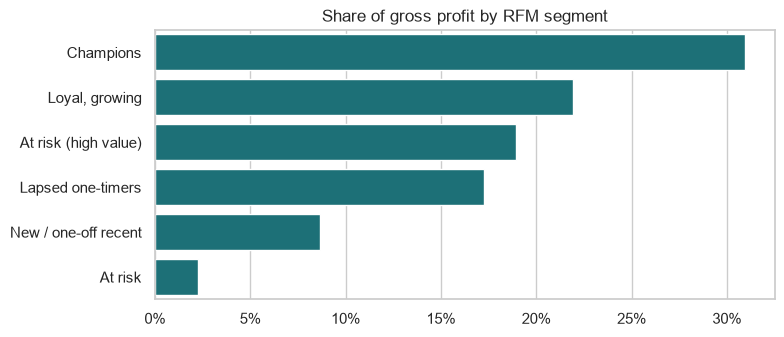

Q26 · RFM: Champions: 33 customers, 31% of profit. At-risk (2+ orders, not recent): 35 customers holding 21% of profit. Lapsed one-timers: 73. List saved to output/rfm_segments.csv for targeting.


In [10]:
rev_cust = ro.groupby("customer_id").agg(last=("order_date", "max"), F=("order_id", "count"), M=("gross_profit", "sum"))
rev_cust["R"] = (DATA_END - rev_cust["last"]).dt.days
rfm = rev_cust.copy()
rfm["r"] = pd.qcut(rfm.R.rank(method="first"), 4, labels=[4, 3, 2, 1]).astype(int)   # recent = 4
rfm["f"] = rfm.F.clip(upper=4)
rfm["m"] = pd.qcut(rfm.M.rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)
def seg(r):
    if r.r >= 3 and r.f >= 3: return "Champions"
    if r.r >= 3 and r.f == 2: return "Loyal, growing"
    if r.r >= 3 and r.f == 1: return "New / one-off recent"
    if r.r <= 2 and r.f >= 2 and r.m >= 3: return "At risk (high value)"
    if r.r <= 2 and r.f >= 2: return "At risk"
    return "Lapsed one-timers"
rfm["segment"] = rfm.apply(seg, axis=1)
rs = rfm.groupby("segment").agg(customers=("F", "size"), avg_orders=("F", "mean"), avg_recency_days=("R", "mean"),
                                 profit=("M", "sum")).sort_values("profit", ascending=False)
rs["profit_share"] = rs.profit / rs.profit.sum()
display(rs)
rfm.reset_index().to_csv(OUTPUT_DIR / "rfm_segments.csv", index=False)
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.barplot(x=rs.profit_share, y=rs.index, ax=ax, color=TEAL); ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Share of gross profit by RFM segment"); ax.set_ylabel(""); ax.set_xlabel("")
save(fig, "q26_rfm")
risk = rs.loc[[s for s in rs.index if s.startswith("At risk")]]
note(26, "RFM",
     f"Champions: {rs.loc['Champions','customers'] if 'Champions' in rs.index else 0} customers, "
     f"{rs.loc['Champions','profit_share'] if 'Champions' in rs.index else 0:.0%} of profit. "
     f"At-risk (2+ orders, not recent): {risk.customers.sum()} customers holding {risk.profit_share.sum():.0%} of profit. "
     f"Lapsed one-timers: {rs.loc['Lapsed one-timers','customers'] if 'Lapsed one-timers' in rs.index else 0}. "
     f"List saved to output/rfm_segments.csv for targeting.")

### Q27 · What predicts becoming a recurring customer?

In [11]:
fo = po[po.n == 1].merge(cust[["customer_id", "segment", "gender", "state", "birth_date"]], on="customer_id")
fo_lines = lines[lines.order_id.isin(fo.order_id)]
top_cat = (fo_lines.groupby(["order_id", "category"]).net_sales.sum().reset_index()
           .sort_values("net_sales").drop_duplicates("order_id", keep="last").set_index("order_id").category)
fo["first_category"] = fo.order_id.map(top_cat)
fo["first_value_band"] = pd.qcut(fo.net_sales, 4, labels=["Low", "Mid-low", "Mid-high", "High"])
fo["first_had_discount"] = (fo.discount_percent > 0) | fo.order_id.isin(fo_lines[fo_lines.item_discount_percent > 0].order_id)
fo["first_cancelled"] = ~fo.is_revenue
fo["age"] = (fo.order_date - fo.birth_date).dt.days / 365.25
fo["recurring"] = fo.customer_id.map(buyers.recurring)
fo["observed"] = fo.customer_id.map(buyers.days_observed)
elig = fo[fo.observed >= 365].copy()      # give everyone at least a year to come back
print(len(elig), "buyers with >= 1 year of history; base repeat rate", f"{elig.recurring.mean():.0%}")

uni = []
for col in ["first_category", "first_value_band", "first_had_discount", "payment_method", "segment", "gender", "first_cancelled"]:
    t = elig.groupby(col, observed=True).recurring.agg(["mean", "size"])
    p = stats.chi2_contingency(pd.crosstab(elig[col], elig.recurring))[1]
    for k, r in t.iterrows(): uni.append(dict(feature=col, value=str(k), repeat_rate=r["mean"], n=int(r["size"]), p_value=p))
uni = pd.DataFrame(uni)
display(uni.style.format({"repeat_rate": "{:.0%}", "p_value": "{:.2f}"}).background_gradient(subset=["repeat_rate"], cmap="Blues"))

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
X = pd.get_dummies(elig[["first_category", "payment_method", "segment", "first_value_band"]].astype(str), drop_first=True)
X["first_had_discount"] = elig.first_had_discount.astype(int); X["age"] = elig.age.fillna(elig.age.median())
X["log_first_value"] = np.log(elig.net_sales.clip(lower=1))
auc = cross_val_score(LogisticRegression(max_iter=2000), X, elig.recurring, cv=5, scoring="roc_auc")
sig = uni[uni.p_value < .05].feature.unique().tolist()
note(27, "Recurring predictors",
     f"Base repeat rate {elig.recurring.mean():.0%} (n={len(elig)}). Features significant at p<0.05: {sig or 'none'}. "
     f"Logistic regression on first-order features: cross-validated AUC {auc.mean():.2f} (±{auc.std():.2f}). "
     f"{'Close to random: first-order attributes do not predict repeat buying; retention must be earned after the first order.' if auc.mean() < .6 else 'Some predictive signal exists.'}")

186 buyers with >= 1 year of history; base repeat rate 58%


,feature,value,repeat_rate,n,p_value
0,first_category,Beauty,53%,45,0.84
1,first_category,Electronics,56%,34,0.84
2,first_category,Fashion,66%,38,0.84
3,first_category,Home & Kitchen,57%,30,0.84
4,first_category,Sports,59%,39,0.84
5,first_value_band,Low,60%,47,0.73
6,first_value_band,Mid-low,51%,45,0.73
7,first_value_band,Mid-high,59%,49,0.73
8,first_value_band,High,62%,45,0.73
9,first_had_discount,False,67%,12,0.75


Q27 · Recurring predictors: Base repeat rate 58% (n=186). Features significant at p<0.05: none. Logistic regression on first-order features: cross-validated AUC 0.42 (±0.11). Close to random: first-order attributes do not predict repeat buying; retention must be earned after the first order.


### Q28 · Does a first-order discount buy loyalty?

In [12]:
t = elig.groupby("first_had_discount").agg(repeat_rate=("recurring", "mean"), n=("recurring", "size"),
                                           first_margin=("gross_profit", "sum"), first_sales=("net_sales", "sum"))
t["first_margin"] = t.first_margin / t.first_sales
display(t.drop(columns="first_sales"))
p = stats.chi2_contingency(pd.crosstab(elig.first_had_discount, elig.recurring))[1]
note(28, "First-order discount",
     f"Repeat rate {t.repeat_rate.get(True, np.nan):.0%} with a discounted first order vs {t.repeat_rate.get(False, np.nan):.0%} without "
     f"(p={p:.2f}); first-order margin {t.first_margin.get(True, np.nan):.1%} vs {t.first_margin.get(False, np.nan):.1%}. "
     f"Discounts {'do not measurably' if p > .05 else 'do'} change repeat behaviour, but they do cost margin.")

,repeat_rate,n,first_margin
first_had_discount,,,
False,0.67,12,0.33
True,0.57,174,0.26


Q28 · First-order discount: Repeat rate 57% with a discounted first order vs 67% without (p=0.75); first-order margin 26.2% vs 33.2%. Discounts do not measurably change repeat behaviour, but they do cost margin.


## C. Products and categories

### Q29 · Pareto: how concentrated is profit?

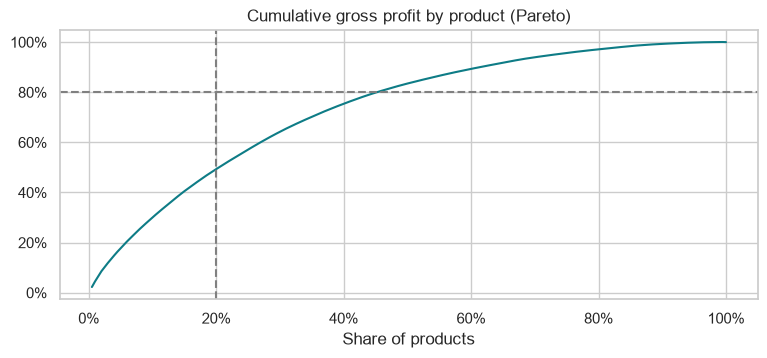

,gp,ns,units,margin
subcategory,,,,
Serum,"2,225,388.89","7,230,469.48",90,0.31
Facewash,"2,161,386.72","7,771,118.12",93,0.28
Yoga Mat,"2,046,829.54","7,079,155.95",96,0.29
T-Shirt,"1,783,935.13","6,238,055.72",106,0.29
Moisturizer,"1,518,465.30","5,589,594.06",106,0.27
Blender,"1,366,661.20","3,421,303.29",62,0.40
Basketball,"1,351,039.12","3,901,175.47",84,0.35
Laptop,"1,349,741.05","4,423,590.71",71,0.31


,gp,ns,units,margin
subcategory,,,,
Dumbbell Set,"493,531.53","2,003,536.33",68,0.25
Air Fryer,"499,610.60","2,193,809.07",35,0.23
Camera,"557,876.14","2,706,875.65",38,0.21
Sneakers,"569,028.35","2,837,896.04",65,0.20
Watch,"670,746.20","2,751,884.23",67,0.24


Q29 · Pareto: Top 20% of products earn 49% of gross profit; 91 of 200 products (46%) make 80%. Profit is spread fairly evenly (no strong 80/20). 1 product(s) net loss-making overall. Top subcategory Serum (₹22.3 L); bottom Dumbbell Set (₹4.9 L).


In [13]:
pp = rl.groupby(["product_id"]).gross_profit.sum().sort_values(ascending=False)
cum = pp.cumsum() / pp.sum()
top20 = cum.iloc[int(len(pp) * .2) - 1]
n80 = (cum < .8).sum() + 1
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(np.arange(1, len(cum) + 1) / len(cum), cum.values, color=TEAL)
ax.axhline(.8, ls="--", color="grey"); ax.axvline(.2, ls="--", color="grey")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Cumulative gross profit by product (Pareto)"); ax.set_xlabel("Share of products"); save(fig, "q29_pareto")
neg_products = (pp < 0).sum()
sub = rl.groupby("subcategory").agg(gp=("gross_profit", "sum"), ns=("net_sales", "sum"), units=("quantity", "sum"))
sub["margin"] = sub.gp / sub.ns
display(sub.sort_values("gp", ascending=False).head(8)); display(sub.sort_values("gp").head(5))
note(29, "Pareto",
     f"Top 20% of products earn {top20:.0%} of gross profit; {n80} of {len(pp)} products ({n80/len(pp):.0%}) make 80%. "
     f"Profit is spread fairly evenly (no strong 80/20). {neg_products} product(s) net loss-making overall. "
     f"Top subcategory {sub.gp.idxmax()} ({L(sub.gp.max())}); bottom {sub.gp.idxmin()} ({L(sub.gp.min())}).")

### Q30 · Which categories are bought together?

In [14]:
basket = rl.groupby(["order_id", "category"]).size().unstack(fill_value=0).gt(0)
n = len(basket); sup = basket.mean()
pairs = []
cats = basket.columns
for i, a in enumerate(cats):
    for b in cats[i + 1:]:
        s_ab = (basket[a] & basket[b]).mean()
        pairs.append(dict(pair=f"{a} + {b}", support=s_ab, lift=s_ab / (sup[a] * sup[b])))
pairs = pd.DataFrame(pairs).sort_values("lift", ascending=False)
display(pairs.style.format({"support": "{:.1%}", "lift": "{:.2f}"}))
multi = (basket.sum(axis=1) >= 2).mean()
note(30, "Basket affinity",
     f"{multi:.0%} of orders span 2+ categories (avg {basket.sum(axis=1).mean():.1f}). Lift ranges "
     f"{pairs.lift.min():.2f}-{pairs.lift.max():.2f}; all near 1, so categories are bought independently. "
     f"No natural cross-sell pair stands out; bundles would need to be designed, not discovered.")

,pair,support,lift
5,Electronics + Home & Kitchen,25.6%,1.05
1,Beauty + Fashion,32.1%,1.05
7,Fashion + Home & Kitchen,27.2%,1.01
3,Beauty + Sports,30.6%,1.00
6,Electronics + Sports,26.9%,0.98
2,Beauty + Home & Kitchen,26.2%,0.96
9,Home & Kitchen + Sports,25.1%,0.94
8,Fashion + Sports,28.2%,0.94
0,Beauty + Electronics,26.2%,0.93
4,Electronics + Fashion,25.6%,0.92


Q30 · Basket affinity: 84% of orders span 2+ categories (avg 2.6). Lift ranges 0.92-1.05; all near 1, so categories are bought independently. No natural cross-sell pair stands out; bundles would need to be designed, not discovered.


### Q31 · Category mix: recurring vs one-time customers

In [15]:
mix = rl.merge(cust[["customer_id", "customer_type"]], on="customer_id")
cm = pd.crosstab(mix.category, mix.customer_type, values=mix.net_sales, aggfunc="sum", normalize="columns")
display(cm.style.format("{:.1%}"))
diff = (cm["Recurring"] - cm["One-Time"]).sort_values()
note(31, "Category mix by customer type",
     f"Largest mix difference: {diff.index[-1]} {diff.iloc[-1]*100:+.1f} pp for recurring, {diff.index[0]} {diff.iloc[0]*100:+.1f} pp. "
     f"Differences are small: recurring customers buy the same mix, just more often.")

customer_type,One-Time,Recurring
category,,
Beauty,22.0%,27.5%
Electronics,20.0%,18.4%
Fashion,20.8%,17.7%
Home & Kitchen,18.0%,16.0%
Sports,19.2%,20.3%


Q31 · Category mix by customer type: Largest mix difference: Beauty +5.5 pp for recurring, Fashion -3.1 pp. Differences are small: recurring customers buy the same mix, just more often.


### Q32 · Is discount margin erosion uniform across categories?

item_discount_percent,0,5,10,15
category,,,,
Beauty,31.8%,29.4%,18.2%,17.6%
Electronics,29.7%,25.4%,22.2%,16.5%
Fashion,29.2%,27.2%,21.9%,13.0%
Home & Kitchen,29.7%,27.6%,23.2%,20.9%
Sports,31.0%,25.3%,20.7%,17.3%


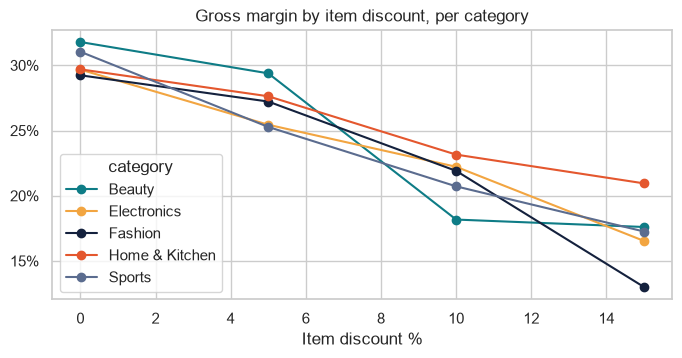

Q32 · Discount erosion by category: Margin falls from 0% to 15% item discount in every category: biggest drop Fashion (16.2 pp), smallest Home & Kitchen (8.7 pp). Erosion is broadly uniform, so a single discount cap policy fits.


In [16]:
er = rl.groupby(["category", "item_discount_percent"]).apply(lambda g: g.gross_profit.sum() / g.net_sales.sum(), include_groups=False).unstack()
display(er.style.format("{:.1%}").background_gradient(axis=None, cmap="RdYlGn"))
drop = (er[0] - er[15]).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 3.5))
er.T.plot(ax=ax, marker="o"); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Gross margin by item discount, per category"); ax.set_xlabel("Item discount %"); save(fig, "q32_discount_erosion")
note(32, "Discount erosion by category",
     f"Margin falls from 0% to 15% item discount in every category: biggest drop {drop.index[0]} ({drop.iloc[0]*100:.1f} pp), "
     f"smallest {drop.index[-1]} ({drop.iloc[-1]*100:.1f} pp). Erosion is broadly uniform, so a single discount cap policy fits.")

## D. Geography, payment, demographics, segment

In [17]:
cb = buyers.reset_index()
cb["age"] = (DATA_END - cb.birth_date).dt.days / 365.25
cb["age_group"] = pd.cut(cb.age, [0, 25, 35, 45, 55, 120], labels=["18-24", "25-34", "35-44", "45-54", "55+"])
cb["gp"] = cb.lifetime_gross_profit.fillna(0)
def profile(col, min_n=8):
    t = cb.groupby(col, observed=True).agg(customers=("customer_id", "size"), repeat_rate=("recurring", "mean"),
                                           profit_per_customer=("gp", "mean"), profit=("gp", "sum"))
    t["profit_share"] = t.profit / t.profit.sum()
    return t[t.customers >= min_n].sort_values("profit", ascending=False)

### Q33 · States and cities

In [18]:
st = profile("state"); display(st)
city = profile("city", 5).head(10); display(city)
rr = stats.chi2_contingency(pd.crosstab(cb.state, cb.recurring))[1]
note(33, "Geography",
     f"Top states by profit: {', '.join(f'{s} {r.profit_share:.0%}' for s, r in st.head(3).iterrows())}. "
     f"Highest profit per customer (n>=8): {st.profit_per_customer.idxmax()} ({L(st.profit_per_customer.max())}); "
     f"lowest: {st.profit_per_customer.idxmin()} ({L(st.profit_per_customer.min())}). Repeat rate differs by state p={rr:.2f}.")

,customers,repeat_rate,profit_per_customer,profit,profit_share
state,,,,,
Maharashtra,47,0.64,"135,661.18","6,376,075.44",0.22
Gujarat,36,0.47,"143,444.07","5,163,986.65",0.18
Karnataka,19,0.53,"129,592.31","2,462,253.84",0.09
Delhi,17,0.59,"136,029.87","2,312,507.82",0.08
Andhra Pradesh,18,0.72,"113,708.00","2,046,743.95",0.07
Madhya Pradesh,14,0.50,"135,880.85","1,902,331.88",0.07
Uttar Pradesh,16,0.38,"107,126.41","1,714,022.57",0.06
Rajasthan,14,0.43,"110,926.35","1,552,968.90",0.05
Telangana,11,0.45,"132,073.11","1,452,804.24",0.05


,customers,repeat_rate,profit_per_customer,profit,profit_share
city,,,,,
Surat,21,0.48,"152,972.57","3,212,424.05",0.11
Mumbai,19,0.58,"137,512.14","2,612,730.65",0.09
Bengaluru,19,0.53,"129,592.31","2,462,253.84",0.09
Delhi,17,0.59,"136,029.87","2,312,507.82",0.08
Nagpur,14,0.64,"159,156.33","2,228,188.64",0.08
Visakhapatnam,18,0.72,"113,708.00","2,046,743.95",0.07
Ahmedabad,15,0.47,"130,104.17","1,951,562.60",0.07
Bhopal,14,0.50,"135,880.85","1,902,331.88",0.07
Lucknow,16,0.38,"107,126.41","1,714,022.57",0.06


Q33 · Geography: Top states by profit: Maharashtra 22%, Gujarat 18%, Karnataka 9%. Highest profit per customer (n>=8): West Bengal (₹1.8 L); lowest: Tamil Nadu (₹1.0 L). Repeat rate differs by state p=0.43.


### Q34 · Payment methods

In [19]:
pm = orders.groupby("payment_method").agg(orders=("order_id", "count"), cancel_return=("is_revenue", lambda s: 1 - s.mean()),
                                          aov=("net_sales", "mean"))
first_pm = fo.groupby("payment_method").recurring.mean().rename("repeat_rate_if_first_order")
pm = pm.join(first_pm); display(pm.style.format({"cancel_return": "{:.1%}", "aov": "{:,.0f}", "repeat_rate_if_first_order": "{:.0%}"}))
p = stats.chi2_contingency(pd.crosstab(orders.payment_method, orders.is_revenue))[1]
note(34, "Payment methods",
     f"Cancel/return rate by method {pm.cancel_return.min():.1%}-{pm.cancel_return.max():.1%} (chi-square p={p:.2f}, "
     f"{'not significant' if p > .05 else 'significant'}). Cash on Delivery: {int(pm.loc['Cash on Delivery','orders'])} orders, "
     f"{pm.loc['Cash on Delivery','cancel_return']:.0%} cancelled - COD is not riskier here.")

,orders,cancel_return,aov,repeat_rate_if_first_order
payment_method,,,,
Cash on Delivery,16,0.0%,"210,756",44%
Credit Card,140,6.4%,"266,537",54%
Debit Card,103,4.9%,"300,735",56%
Netbanking,59,1.7%,"289,584",58%
UPI,87,4.6%,"283,966",46%


Q34 · Payment methods: Cancel/return rate by method 0.0%-6.4% (chi-square p=0.57, not significant). Cash on Delivery: 16 orders, 0% cancelled - COD is not riskier here.


### Q35 · Age and gender

In [20]:
ag = profile("age_group"); gd = profile("gender"); display(ag); display(gd)
p_age = stats.kruskal(*[g.gp.values for _, g in cb.groupby("age_group", observed=True)]).pvalue
note(35, "Demographics",
     f"Profit per customer by age group {L(ag.profit_per_customer.min())}-{L(ag.profit_per_customer.max())} "
     f"(Kruskal p={p_age:.2f}); repeat rate by gender {gd.repeat_rate.min():.0%}-{gd.repeat_rate.max():.0%}. "
     f"Groups are small (18-24 has {int(ag.loc['18-24','customers']) if '18-24' in ag.index else 0} buyers); "
     f"no demographic is a reliable targeting lever.")

,customers,repeat_rate,profit_per_customer,profit,profit_share
age_group,,,,,
25-34,54,0.56,"138,438.55","7,475,681.81",0.26
45-54,51,0.53,"124,648.70","6,357,083.74",0.22
55+,51,0.51,"119,464.78","6,092,704.01",0.21
35-44,45,0.47,"110,230.58","4,960,376.08",0.17
18-24,19,0.63,"197,765.69","3,757,548.08",0.13


,customers,repeat_rate,profit_per_customer,profit,profit_share
gender,,,,,
Female,83,0.57,"137,909.36","11,446,477.09",0.40
Other,76,0.53,"128,889.21","9,795,580.15",0.34
Male,61,0.48,"121,333.38","7,401,336.47",0.26


Q35 · Demographics: Profit per customer by age group ₹1.1 L-₹2.0 L (Kruskal p=0.11); repeat rate by gender 48%-57%. Groups are small (18-24 has 19 buyers); no demographic is a reliable targeting lever.


### Q36 · Retail vs Wholesale

In [21]:
sg = profile("segment")
oseg = ro.merge(cust[["customer_id", "segment"]], on="customer_id").groupby("segment").agg(
    aov=("net_sales", "mean"), units_per_order=("units", "mean"), margin=("gross_profit", "sum"), ns=("net_sales", "sum"))
oseg["margin"] = oseg.margin / oseg.ns
display(sg.join(oseg.drop(columns="ns")))
p = stats.mannwhitneyu(cb[cb.segment == "Retail"].gp, cb[cb.segment == "Wholesale"].gp).pvalue
note(36, "Retail vs Wholesale",
     f"Wholesale: {int(sg.loc['Wholesale','customers'])} buyers, repeat {sg.loc['Wholesale','repeat_rate']:.0%}, "
     f"{L(sg.loc['Wholesale','profit_per_customer'])}/customer; Retail: {int(sg.loc['Retail','customers'])} buyers, "
     f"repeat {sg.loc['Retail','repeat_rate']:.0%}, {L(sg.loc['Retail','profit_per_customer'])}/customer (p={p:.2f}). "
     f"The segments behave alike; the label carries little signal.")

,customers,repeat_rate,profit_per_customer,profit,profit_share,aov,units_per_order,margin
segment,,,,,,,,
Retail,179,0.54,"131,037.49","23,455,710.92",0.82,"286,971.75",5.06,0.27
Wholesale,41,0.49,"126,528.85","5,187,682.80",0.18,"254,713.39",4.84,0.26


Q36 · Retail vs Wholesale: Wholesale: 41 buyers, repeat 49%, ₹1.3 L/customer; Retail: 179 buyers, repeat 54%, ₹1.3 L/customer (p=0.93). The segments behave alike; the label carries little signal.


## Summary

In [22]:
F = pd.DataFrame(findings)
F.to_csv(OUTPUT_DIR / "eda_findings.csv", index=False)
pd.set_option("display.max_colwidth", None)
F

,q,topic,finding
0,19,Trend & seasonality,"Avg 11.4 revenue orders and ₹8.4 L gross profit per month (CV 41%). STL seasonal strength 0.62, trend strength 0.17, but estimated from fewer than 3 yearly cycles, so any seasonality is unconfirmed. Best month on average: Mar, weakest: Nov. Weekday mix chi-square p=0.51 (no weekday effect)."
1,20,Like-for-like growth,"Jan-Oct gross profit: 2023 ₹99.5 L, 2024 ₹79.1 L (-21%), 2025 ₹83.6 L (+6%). Orders 123 → 111 → 114; active customers 108 → 84 → 90."
2,21,AOV drivers,AOV ranges ₹2.4 L-₹3.1 L by quarter. Correlation of log AOV with units/order 0.70 vs with net price/unit 0.67: AOV moves mainly with basket size (units). Discount rate range 7.4%-12.2%.
3,22,Cohort retention,"Of buyers observed long enough, 10% order again within 90 days, 20% within 180 days, 34% within 365 days. Cohort sizes shrink from 32 buyers/quarter in 2023 to 7 in the last 4 quarters."
4,23,Time to 2nd order,"Median gap 1st→2nd order 254 days (IQR 131-527). KM probability of a 2nd order: 10% by 90 d, 20% by 180 d, 35% by 1 yr, 54% by 2 yrs. 38% of second orders come after a year, so 'lost' should not be declared before ~12 months of silence."
5,24,Acquisition decline,"New buyers by year: {2023: 128, 2024: 64, 2025: 28}. Sign-ups (join_date) by year: {2022: 113, 2023: 123, 2024: 64}; the last sign-up is 25 Sep 2024, with none in the following 13 months. New buyers track sign-ups, so the drop is a top-of-funnel problem (or an extract cut-off), not a conversion problem. 80 registered customers are still unconverted. Repeat orders rose from 17% to 75% of orders."
6,25,Never-ordered profile,"80 never-ordered customers. Median age 44 vs 43 for buyers (p=0.57); segment difference p=0.56. Top states: {'Maharashtra': 18, 'Gujarat': 11, 'Karnataka': 8}. They look like buyers demographically: non-conversion is not explained by profile."
7,26,RFM,"Champions: 33 customers, 31% of profit. At-risk (2+ orders, not recent): 35 customers holding 21% of profit. Lapsed one-timers: 73. List saved to output/rfm_segments.csv for targeting."
8,27,Recurring predictors,Base repeat rate 58% (n=186). Features significant at p<0.05: none. Logistic regression on first-order features: cross-validated AUC 0.42 (±0.11). Close to random: first-order attributes do not predict repeat buying; retention must be earned after the first order.
9,28,First-order discount,"Repeat rate 57% with a discounted first order vs 67% without (p=0.75); first-order margin 26.2% vs 33.2%. Discounts do not measurably change repeat behaviour, but they do cost margin."
